# Lab 10 — Fine-tuning `bert-base-cased` cho Extractive QA (SQuAD v1.1)

Huấn luyện được chạy bằng script (để chạy nền trên server22, tránh timeout của notebook):

```bash
python qa_model.py --tag main --max_length 384 --stride 128 --epochs 2 --save_model          # Experiment 2
python qa_model.py --tag len128 --max_length 128 --stride 42  --epochs 1 --train_samples 20000  # Experiment 1
python qa_model.py --tag len256 --max_length 256 --stride 85  --epochs 1 --train_samples 20000
python qa_model.py --tag len384 --max_length 384 --stride 128 --epochs 1 --train_samples 20000
python baseline_qa.py
python analyze_qa.py
```

Notebook này nạp lại log/checkpoint, trình bày learning curves, kết quả và chạy suy luận với model đã fine-tune.
Phần thân của vòng lặp huấn luyện (loss tường minh) được trích ở mục 1.

In [1]:
import json, inspect
import pandas as pd
from IPython.display import Image, display
import qa_model
from qa_model import qa_loss, load_qa_model, answer_question
pd.set_option('display.max_colwidth', 120)
print(inspect.getsource(qa_loss))

def qa_loss(start_logits, end_logits, start_positions, end_positions):
    """L = (L_start + L_end) / 2 with softmax over sequence positions."""
    import torch.nn.functional as F
    ignored = start_logits.size(1)
    start_positions = start_positions.clamp(0, ignored)
    end_positions = end_positions.clamp(0, ignored)
    l_start = F.cross_entropy(start_logits.float(), start_positions, ignore_index=ignored)
    l_end = F.cross_entropy(end_logits.float(), end_positions, ignore_index=ignored)
    return (l_start + l_end) / 2, l_start, l_end



## 1. Cấu hình & thống kê feature của model chính

In [2]:
summary = json.load(open('outputs/main/summary.json'))
cfg = summary['config']
pd.Series({k: summary[k] for k in ['train_examples', 'train_features', 'windows_per_example',
                                   'features_answer_in_window_pct', 'dev_features', 'test_features',
                                   'train_time_sec', 'gpu']} | {f'cfg.{k}': v for k, v in cfg.items()})

train_examples                                     85579
train_features                                     86696
windows_per_example                             1.013052
features_answer_in_window_pct                  98.968811
dev_features                                        2033
test_features                                      10822
train_time_sec                               4613.774858
gpu                              NVIDIA GeForce RTX 3060
cfg.tag                                             main
cfg.model                                bert-base-cased
cfg.max_length                                       384
cfg.stride                                           128
cfg.epochs                                             2
cfg.batch_size                                         8
cfg.grad_accum                                         2
cfg.lr                                           0.00003
cfg.weight_decay                                    0.01
cfg.warmup                     

## 2. Learning curves (training loss, validation loss, EM, F1)

,step,epoch,train_loss,train_start_loss,train_end_loss,val_loss,val_em,val_f1,train_time_sec
0,1354,0.2499,2.4883,2.5402,2.4364,1.1176,62.2277,75.5674,587.6454
1,2708,0.4997,1.2536,1.3079,1.1993,0.9475,66.3366,78.8898,1143.2172
2,4062,0.7496,1.1158,1.1713,1.0603,0.8600,68.7129,81.6493,1710.2630
3,5416,0.9994,1.0508,1.1068,0.9948,0.8065,71.2871,83.0921,2274.2166
4,6770,1.2493,0.7695,0.8151,0.7239,0.8042,70.7921,83.0017,2857.2308
5,8124,1.4992,0.7480,0.7974,0.6986,0.8216,71.7822,83.7554,3450.8420
6,9478,1.7490,0.7400,0.7874,0.6927,0.7805,72.0297,84.5884,4018.8733
7,10832,1.9989,0.7294,0.7787,0.6800,0.7694,72.6733,84.7155,4611.0679
8,10838,2.0000,0.7201,0.7451,0.6951,0.7694,72.7228,84.7290,4613.7749


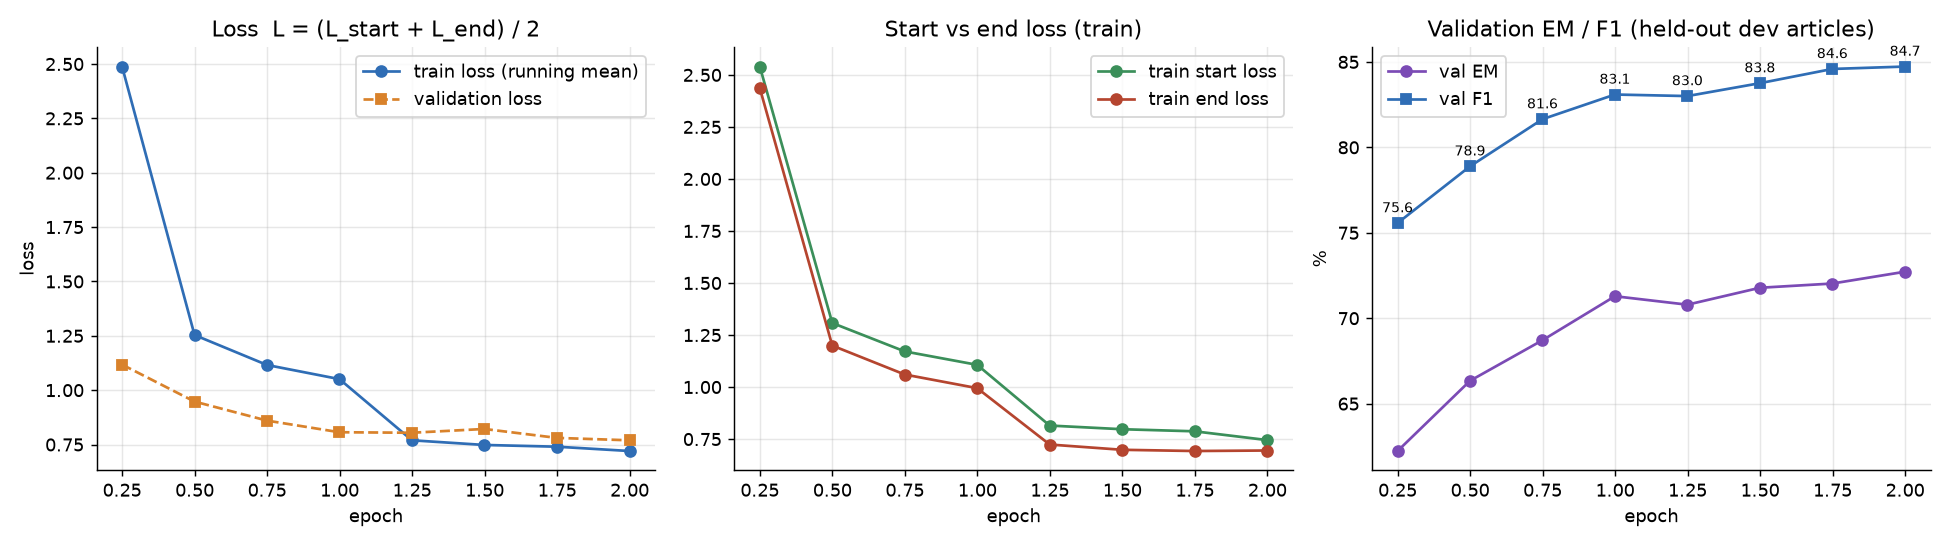

In [3]:
hist = pd.DataFrame(json.load(open('outputs/main/history.json')))
display(hist.round(4))
display(Image('learning_curves.png'))

## 3. Kết quả trên test (SQuAD v1.1 dev chính thức, 10,570 câu hỏi)

,experiment,model,max_length,stride,train_examples,epochs,EM,F1,train_time_min
0,Exp3: model comparison,Baseline (keyword overlap + answer-type rules),-,-,0,0,15.71,28.63,0.0
1,Exp2/3: model comparison,bert-base-cased fine-tuned,384,128,85579,2,81.40,88.73,76.9
2,Exp1: context length,bert-base-cased fine-tuned,128,42,20000,1,73.30,81.92,10.8
3,Exp1: context length,bert-base-cased fine-tuned,256,85,20000,1,72.35,81.67,7.6
4,Exp1: context length,bert-base-cased fine-tuned,384,128,20000,1,71.89,81.18,9.5


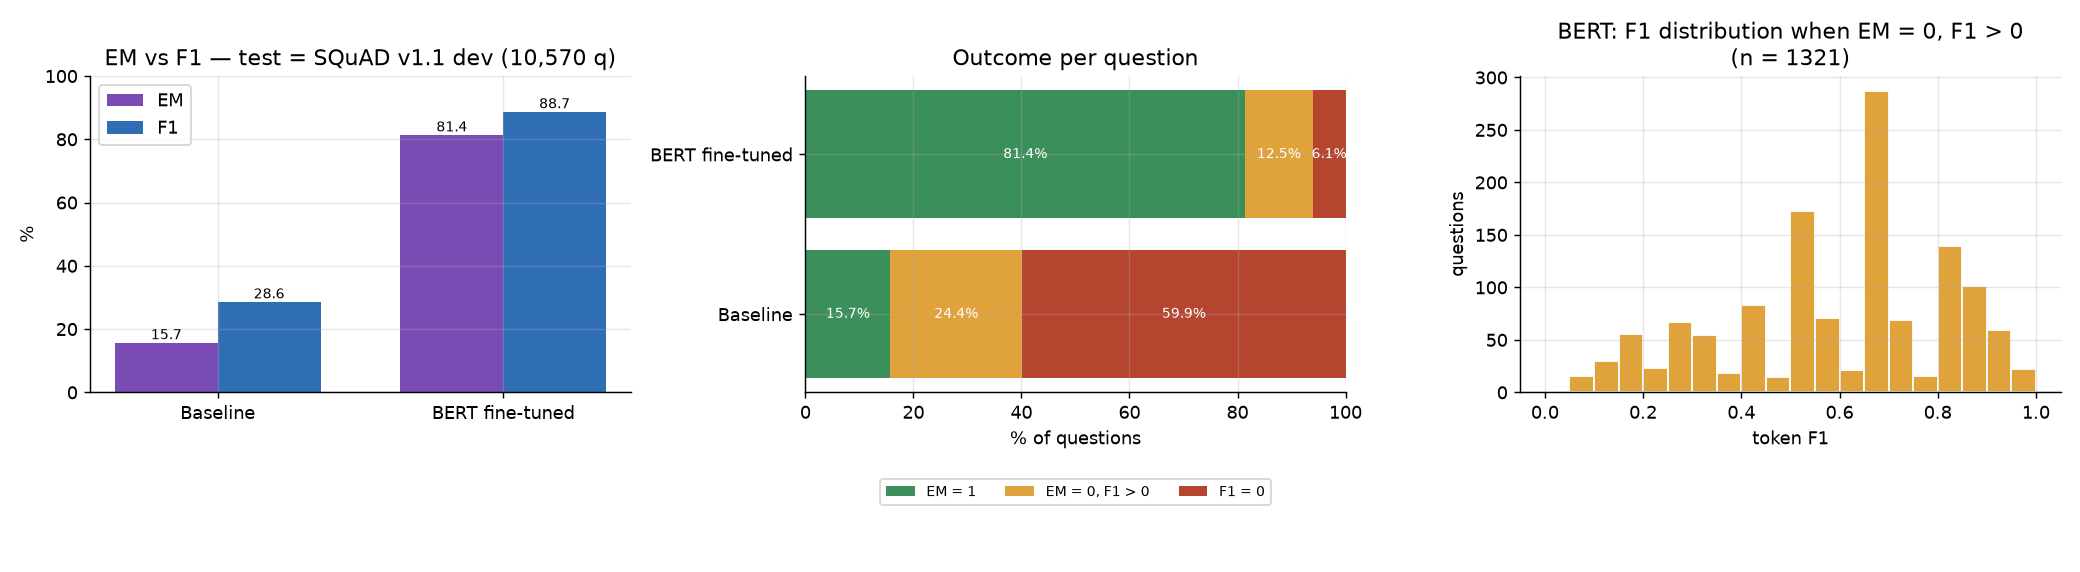

In [4]:
display(pd.read_csv('results.csv'))
display(Image('em_f1_analysis.png'))

## 4. Experiment 1 — Context length

In [5]:
rows = []
for L in [128, 256, 384]:
    s = json.load(open(f'outputs/len{L}/summary.json'))
    rows.append({'max_length': L, 'stride': s['config']['stride'], 'windows/example': round(s['windows_per_example'], 3),
                 '% train windows w/ answer': round(s['features_answer_in_window_pct'], 2),
                 'EM': round(s['test']['exact_match'], 2), 'F1': round(s['test']['f1'], 2),
                 'train_time_min': round(s['train_time_sec'] / 60, 1)})
pd.DataFrame(rows)

,max_length,stride,windows/example,% train windows w/ answer,EM,F1,train_time_min
0,128,42,2.216,54.41,73.30,81.92,10.8
1,256,85,1.122,91.22,72.35,81.67,7.6
2,384,128,1.013,99.04,71.89,81.18,9.5


## 5. Answer length & lexical overlap

,answer_length,n,bert_EM,bert_F1,baseline_EM,baseline_F1,bert_F1_minus_EM
0,1,3429,85.13,89.37,22.95,32.22,4.24
1,2–3,4575,83.56,89.96,14.73,29.39,6.40
2,4–6,1648,78.40,88.42,10.25,24.13,10.02
3,7+,918,62.09,80.81,3.38,19.54,18.72


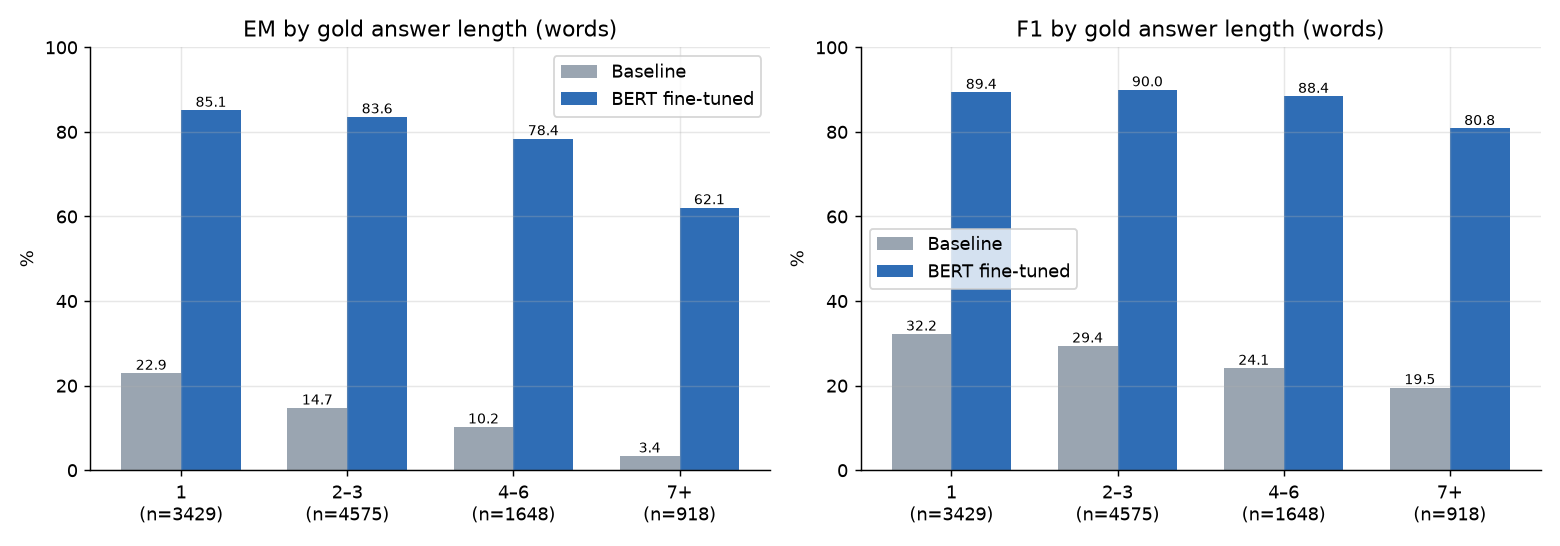

,overlap_group,n,mean_overlap,bert_EM,bert_F1,baseline_EM,baseline_F1
0,high overlap (≥0.80),2847,0.930,87.43,93.53,24.69,40.05
1,low overlap (≤0.40),2956,0.228,73.17,82.19,6.50,15.80
2,middle,4767,0.609,82.90,89.93,16.07,29.76


,condition,n,windows/example,bert_em,bert_f1,baseline_em,baseline_f1
0,original,1000,1.017,81.8,90.05,18.8,32.00
1,irrelevant_append,1000,1.309,81.0,88.88,18.8,32.00
2,irrelevant_prepend,1000,1.309,78.4,86.72,18.6,31.69
3,distractor_addsent,1000,1.020,42.9,47.18,10.2,16.95
4,distractor_contradictory,1000,1.020,29.4,32.47,4.8,8.44
5,shuffled_sentences,1000,1.017,79.5,88.75,18.3,32.05


In [6]:
analysis = json.load(open('outputs/analysis.json'))
display(pd.DataFrame(analysis['answer_length']))
display(Image('answer_length_analysis.png'))
display(pd.DataFrame(analysis['lexical_overlap']))
display(pd.DataFrame(analysis['robustness']))

## 6. Suy luận với model đã fine-tune

In [7]:
tok, model, device = load_qa_model('outputs/main/model')
ctx = 'The capital of France is Paris. The French government is based in Paris.'
for q in ['What city is the capital of France?', 'Where is the French government based?',
          'What is the capital of Germany?']:
    r = answer_question(q, ctx, tok, model, device)
    print(f"{q:45s} -> {r['text']!r:12s} chars=({r['start_char']},{r['end_char']}) score={r['score']:.2f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

What city is the capital of France?           -> 'Paris'      chars=(25,30) score=10.88


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Where is the French government based?         -> 'Paris'      chars=(66,71) score=11.32


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

What is the capital of Germany?               -> 'Paris'      chars=(25,30) score=5.38


Câu hỏi cuối ("capital of Germany") **không có đáp án** trong context nhưng model SQuAD v1.1 vẫn buộc phải trả về một span
→ minh họa hạn chế của extractive QA không có nhánh no-answer (Mục 26).